In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score

from sklearn.preprocessing import MinMaxScaler

pd.options.display.max_columns = 100

# Unstructured data(text)

## Initial investigation

In [2]:
tweets = pd.read_csv('twitter_airline_reviews_tdidf.csv')

C:\Users\Inesa\AppData\Local\Temp\ipykernel_13340\4062529468.py:1: DtypeWarning: Columns (6,8,11) have mixed types. Specify dtype option on import or set low_memory=False.
  tweets = pd.read_csv('twitter_airline_reviews_tdidf.csv')


In [3]:
tweets.columns

Index(['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence',
       'negativereason', 'negativereason_confidence', 'airline',
       'airline_sentiment_gold', 'name', 'negativereason_gold',
       'retweet_count',
       ...
       'zipper', 'zj76', 'zkatcher', 'zombie', 'zone', 'zoom', 'zrh',
       'zrh_airport', 'zukes', 'zurich'],
      dtype='object', length=11181)

In [4]:
tweets.head()

,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone,company_tag,cleaned_text,cleaned_text_nltk,000ft,000lbs,00a,00am,00p,00pm,01pm,05am,05pm,07p,0_0,0xjared,1000cost,1030pm,10a,10am,10d,10f,10hrs,10m,10min,10mins,10p,10pm,10th,10voucherwhatajoke,10x,10x9x17,10yr,1120am,1130pm,11a,...,yourock,yourphonesystemsucks,yourstoryhere,yousuck,yout,youth,yow,yponthebeat,ypu,yr,yrs,ystday,ystrdy,yuck,yucki,yul,yuma,yummy,yup,yvonne,yvonneokaka,yvr,ywg,yxe,yxu,yyc,yyj,yyz,yyzua70435,z1,zabsonre,zacks_com,zagging,zakkohane,zambia,zcc82u,zero,zfv,zig,zip,zipper,zj76,zkatcher,zombie,zone,zoom,zrh,zrh_airport,zukes,zurich
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada),@VirginAmerica,What @dhepburn said.,dhepburn say,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada),@VirginAmerica,plus you've added commercials to the experienc...,plus added commercial experience ... tacky,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada),@VirginAmerica,I didn't today... Must mean I need to take ano...,today ... must mean need take another trip,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada),@VirginAmerica,"it's really aggressive to blast obnoxious ""ent...",really aggressive blast obnoxious `` entertain...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada),@VirginAmerica,and it's a really big bad thing about it,really big bad thing,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [14]:
proportions = tweets['airline_sentiment'].value_counts(normalize=True)
proportions

airline_sentiment
negative    0.626913
neutral     0.211680
positive    0.161407
Name: proportion, dtype: float64

In [16]:
target_n = 100

In [17]:
sample_sizes = (proportions * target_n).round().astype(int)
sample_sizes

airline_sentiment
negative    63
neutral     21
positive    16
Name: proportion, dtype: int64

In [18]:
tweets_sample_stratified = tweets.groupby('airline_sentiment', group_keys=False).apply(
    lambda x: x.sample(n=sample_sizes.loc[x.name], random_state=42)
)

C:\Users\Inesa\AppData\Local\Temp\ipykernel_13340\1667227297.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tweets_sample_stratified = tweets.groupby('airline_sentiment', group_keys=False).apply(


In [19]:
tweets_sample_stratified

,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone,company_tag,cleaned_text,cleaned_text_nltk,000ft,000lbs,00a,00am,00p,00pm,01pm,05am,05pm,07p,0_0,0xjared,1000cost,1030pm,10a,10am,10d,10f,10hrs,10m,10min,10mins,10p,10pm,10th,10voucherwhatajoke,10x,10x9x17,10yr,1120am,1130pm,11a,...,yourock,yourphonesystemsucks,yourstoryhere,yousuck,yout,youth,yow,yponthebeat,ypu,yr,yrs,ystday,ystrdy,yuck,yucki,yul,yuma,yummy,yup,yvonne,yvonneokaka,yvr,ywg,yxe,yxu,yyc,yyj,yyz,yyzua70435,z1,zabsonre,zacks_com,zagging,zakkohane,zambia,zcc82u,zero,zfv,zig,zip,zipper,zj76,zkatcher,zombie,zone,zoom,zrh,zrh_airport,zukes,zurich
1151,569913595762311168,negative,1.0000,longlines,0.6742,United,NaN,brianaverna,NaN,0,@united gate C 24 IAD. U released passengers t...,NaN,2015-02-23 09:36:04 -0800,"CT, NY and most other states",Eastern Time (US & Canada),@united,gate C 24 IAD. U released passengers to board ...,gate c iad release passenger board w/others de...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9111,570215234088116224,negative,0.6452,Late Flight,0.6452,US Airways,NaN,stevan_hicks,NaN,0,@USAirways 1729 connecting in charlotte to hou...,NaN,2015-02-24 05:34:40 -0800,NaN,NaN,@USAirways,1729 connecting in charlotte to houston. Mecha...,connect charlotte houston mechanical issue det...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3326,568526349565972480,negative,1.0000,Customer Service Issue,0.6533,United,NaN,deannachurch,NaN,0,@united installed and working are not the same...,NaN,2015-02-19 13:43:39 -0800,"Silver Spring,MD",Pacific Time (US & Canada),@united,installed and working are not the same. Kicked...,instal work kick hour would let back four wast...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
10891,568796449863028736,negative,1.0000,Can't Tell,0.6509,US Airways,NaN,mjmena001,NaN,0,"@USAirways now I am on flight to FLL, and told...",NaN,2015-02-20 07:36:56 -0800,West Palm,NaN,@USAirways,"now I am on flight to FLL, and told to take a ...",flight fll tell take train back pbi get car tr...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
11322,568213769798578176,negative,1.0000,Can't Tell,0.6465,US Airways,NaN,LinseyGarwood,NaN,0,@USAirways ...Loosing a lot of business by usi...,NaN,2015-02-18 17:01:34 -0800,NaN,NaN,@USAirways,...Loosing a lot of business by using Barclays...,... loosing lot business use barclays believe ...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [20]:
tweets_sample_stratified['airline_sentiment'].value_counts(normalize=True)

airline_sentiment
negative    0.63
neutral     0.21
positive    0.16
Name: proportion, dtype: float64

## Data analysis

## Train-test split

In [90]:
y = tweets_sample_stratified['airline_sentiment']
X = tweets_sample_stratified.loc[:, '000ft':]

In [91]:
X

,000ft,000lbs,00a,00am,00p,00pm,01pm,05am,05pm,07p,0_0,0xjared,1000cost,1030pm,10a,10am,10d,10f,10hrs,10m,10min,10mins,10p,10pm,10th,10voucherwhatajoke,10x,10x9x17,10yr,1120am,1130pm,11a,11am,11c,11pm,11th,1215pm,1230am,125k,12a,12am,12b,12h,12h30am,12pm,12th,12thman,130am,13ewr,13pm,...,yourock,yourphonesystemsucks,yourstoryhere,yousuck,yout,youth,yow,yponthebeat,ypu,yr,yrs,ystday,ystrdy,yuck,yucki,yul,yuma,yummy,yup,yvonne,yvonneokaka,yvr,ywg,yxe,yxu,yyc,yyj,yyz,yyzua70435,z1,zabsonre,zacks_com,zagging,zakkohane,zambia,zcc82u,zero,zfv,zig,zip,zipper,zj76,zkatcher,zombie,zone,zoom,zrh,zrh_airport,zukes,zurich
1151,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9111,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3326,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
10891,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
11322,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7673,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8438,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4577,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,

In [92]:
y.value_counts()

airline_sentiment
negative    63
neutral     21
positive    16
Name: count, dtype: int64

In [93]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 2022)

In [94]:
y_train.value_counts()

airline_sentiment
negative    45
neutral     14
positive    11
Name: count, dtype: int64

In [95]:
y_test.value_counts()

airline_sentiment
negative    18
neutral      7
positive     5
Name: count, dtype: int64

# Classification models

More types of classifiers built in scikit learn and their visualizations: https://scikit-learn.org/stable/auto_examples/classification/plot_classifier_comparison.html

## KNN (K Nearest Neighbors)

https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html

### Model training

In [96]:
from sklearn.neighbors import KNeighborsClassifier

In [97]:
knn = KNeighborsClassifier(n_neighbors = 5)

# default n_neighbors = 5

In [98]:
knn.fit(X_train, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


### Model evaluation

In [99]:
y_predict = knn.predict(X_test)
y_train_estimated = knn.predict(X_train)

In [100]:
y_predict

array(['negative', 'negative', 'negative', 'negative', 'negative',
       'negative', 'negative', 'negative', 'negative', 'negative',
       'negative', 'neutral', 'negative', 'negative', 'negative',
       'negative', 'negative', 'negative', 'negative', 'negative',
       'negative', 'negative', 'negative', 'negative', 'negative',
       'negative', 'negative', 'negative', 'negative', 'positive'],
      dtype=object)

In [101]:
y_test

6055      neutral
12183     neutral
12240     neutral
3709     negative
9902     negative
3418     negative
4367     negative
8438     positive
5585      neutral
11883    negative
4312     positive
10891    negative
10852     neutral
1553     negative
9100     negative
10237    negative
614      negative
1748     negative
1190     negative
6558     positive
12645    negative
6396     positive
6590      neutral
14461    negative
1073     negative
8274      neutral
10554    negative
13776    negative
11322    negative
4577     positive
Name: airline_sentiment, dtype: object

In [102]:
df_test_predict = pd.DataFrame({'y_test': y_test, 'y_predict' : y_predict})
df_test_predict

,y_test,y_predict
6055,neutral,negative
12183,neutral,negative
12240,neutral,negative
3709,negative,negative
9902,negative,negative
3418,negative,negative
4367,negative,negative
8438,positive,negative
5585,neutral,negative
11883,negative,negative


#### Evaluation metrics

In [103]:
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score

##### **Accuracy score**

In [104]:
print('Train accuracy: ', accuracy_score(y_train, y_train_estimated))
print('Test accuracy: ', accuracy_score(y_test, y_predict))

Train accuracy:  0.7571428571428571
Test accuracy:  0.6


##### **Precision score**

**pos_label** parameter specifies which class should be treated as the "positive" class for binary classification metrics.

Precision is defined as the ratio of True Positives (TP) to all predicted positives $(\text{TP} + \text{False Positives})$.

By setting pos_label='Female', the precision score returned is the model's ability to **correctly identify a 'Female' prediction** when it is making one.

In [105]:
print('Train precision: ',precision_score(y_train, y_train_estimated, pos_label='negative', average = 'micro'))
print('Test precision: ',precision_score(y_test, y_predict, pos_label='negative', average = 'micro'))

Train precision:  0.7571428571428571
Test precision:  0.6


C:\Users\Inesa\anaconda3\envs\L7_AI\Lib\site-packages\sklearn\metrics\_classification.py:1759: UserWarning: Note that pos_label (set to 'negative') is ignored when average != 'binary' (got 'micro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn(
C:\Users\Inesa\anaconda3\envs\L7_AI\Lib\site-packages\sklearn\metrics\_classification.py:1759: UserWarning: Note that pos_label (set to 'negative') is ignored when average != 'binary' (got 'micro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn(


##### **Recall score**

Here, recall represents **the proportion of all actual 'Female' instances that were correctly identified by the model**.

It answers the question: **"Out of all the truly 'Female' people, how many did the model 'recall' or catch?"**

In [106]:
print('Train recall: ',recall_score(y_train, y_train_estimated, pos_label='negative', average = 'micro'))
print('Test recall: ',recall_score(y_test, y_predict, pos_label='negative', average = 'micro'))

Train recall:  0.7571428571428571
Test recall:  0.6


C:\Users\Inesa\anaconda3\envs\L7_AI\Lib\site-packages\sklearn\metrics\_classification.py:1759: UserWarning: Note that pos_label (set to 'negative') is ignored when average != 'binary' (got 'micro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn(
C:\Users\Inesa\anaconda3\envs\L7_AI\Lib\site-packages\sklearn\metrics\_classification.py:1759: UserWarning: Note that pos_label (set to 'negative') is ignored when average != 'binary' (got 'micro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn(


##### **F1 score**

In [107]:
print('Train F1: ',f1_score(y_train, y_train_estimated, pos_label='negative', average = 'micro'))
print('Test F1: ',f1_score(y_test, y_predict, pos_label='negative', average = 'micro'))

Train F1:  0.7571428571428571
Test F1:  0.6


C:\Users\Inesa\anaconda3\envs\L7_AI\Lib\site-packages\sklearn\metrics\_classification.py:1759: UserWarning: Note that pos_label (set to 'negative') is ignored when average != 'binary' (got 'micro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn(
C:\Users\Inesa\anaconda3\envs\L7_AI\Lib\site-packages\sklearn\metrics\_classification.py:1759: UserWarning: Note that pos_label (set to 'negative') is ignored when average != 'binary' (got 'micro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn(


##### **Confusion Matrix**

In [108]:
from sklearn.metrics import confusion_matrix

In [109]:
conf_mx_train = confusion_matrix(y_train, y_train_estimated, labels = ['negative', 'neutral', 'positive'])
conf_mx_test = confusion_matrix(y_test, y_predict, labels = ['negative', 'neutral', 'positive'])
conf_mx_test

array([[17,  1,  0],
       [ 7,  0,  0],
       [ 4,  0,  1]])

[None, None, None]

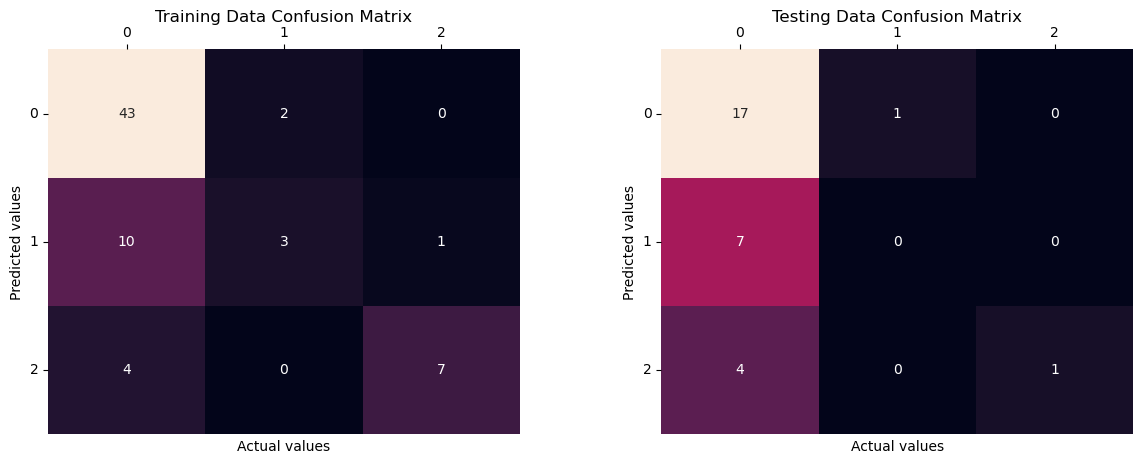

In [110]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
plt.subplots_adjust(wspace=0.3)

ax = sns.heatmap(conf_mx_train, annot=True, fmt="d", cbar=False, ax=ax1,)

ax1.set_title('Training Data Confusion Matrix', y=1.05)
ax1.xaxis.tick_top()
ax1.set_xlabel('Actual values')
ax1.set_ylabel('Predicted values')
plt.setp(ax1.get_yticklabels(), rotation=0)

ax = sns.heatmap(conf_mx_test, annot=True, fmt="d", cbar=False, ax=ax2,)

ax2.set_title('Testing Data Confusion Matrix', y=1.05)
ax2.xaxis.tick_top()
ax2.set_xlabel('Actual values')
ax2.set_ylabel('Predicted values')
plt.setp(ax2.get_yticklabels(), rotation=0)

#### Validation

In [111]:
def cross_val_results(X, y, model=knn, scoring='accuracy', cv=5):
    scores = cross_val_score(model, X, y, scoring='accuracy', cv=5)

    print(f"Scores: {scores}")
    print(f"Mean: {scores.mean()}")
    print(f"Std: {scores.std()}")
    return scores

In [112]:
cross_val_results(X, y)

Scores: [0.6  0.75 0.65 0.6  0.75]
Mean: 0.67
Std: 0.06782329983125268


array([0.6 , 0.75, 0.65, 0.6 , 0.75])

### Model tuning

Tunable Parameters:

1. $\text{n\_neighbors}$ - Determines the number of closest data points in the training set that are used to vote on the classification of a new data point.
- small n -> High Variance(overfitting)
- large n -> High Bias(underfitting)
2. $\text{metric}$  -> p(default p=2) - Specifies the mathematical formula used to determine "closeness."
- Euclidean(p=2)
- Manhattan(p=1)
- Minkowski(p=2)
- Chebyshev
3. $\text{weights}$ - Determines the influence of each neighbor on the final classification decision.
- Uniform(Default) - All neighbors are weighted equally. A simple majority vote determines the class.
- Distance - Closer neighbors have a greater influence than neighbors further away. The weight is inversely proportional to the distance from the query point. This often improves performance by giving more importance to the most relevant local points.

In [115]:
knn_2 = KNeighborsClassifier(n_neighbors = 3, weights = 'uniform', p = 1)
knn_2.fit(X_train, y_train)
y_predict = knn_2.predict(X_test)
y_train_estimated = knn_2.predict(X_train)

In [118]:
def evaluation_results(y_train, y_train_estimated, y_test, y_predict):
    print('Train accuracy: ', accuracy_score(y_train, y_train_estimated))
    print('Test accuracy: ', accuracy_score(y_test, y_predict))
    
    print('Train precision: ',precision_score(y_train, y_train_estimated, pos_label='negative', average = 'micro'))
    print('Test precision: ',precision_score(y_test, y_predict, pos_label='negative', average = 'micro'))
    
    print('Train recall: ',recall_score(y_train, y_train_estimated, pos_label='negative', average = 'micro'))
    print('Test recall: ',recall_score(y_test, y_predict, pos_label='negative', average = 'micro'))
    
    print('Train F1: ',f1_score(y_train, y_train_estimated, pos_label='negative', average = 'micro'))
    print('Test F1: ',f1_score(y_test, y_predict, pos_label='negative', average = 'micro'))
    
    conf_mx_train = confusion_matrix(y_train, y_train_estimated, labels = ['negative', 'neutral', 'positive'])
    conf_mx_test = confusion_matrix(y_test, y_predict, labels = ['negative', 'neutral', 'positive'])
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    plt.subplots_adjust(wspace=0.3)
    
    ax = sns.heatmap(conf_mx_train, annot=True, fmt="d", cbar=False, ax=ax1,)
    
    ax1.set_title('Training Data Confusion Matrix', y=1.05)
    ax1.xaxis.tick_top()
    ax1.set_xlabel('Actual values')
    ax1.set_ylabel('Predicted values')
    plt.setp(ax1.get_yticklabels(), rotation=0)
    
    ax = sns.heatmap(conf_mx_test, annot=True, fmt="d", cbar=False, ax=ax2,)
    
    ax2.set_title('Testing Data Confusion Matrix', y=1.05)
    ax2.xaxis.tick_top()
    ax2.set_xlabel('Actual values')
    ax2.set_ylabel('Predicted values')
    plt.setp(ax2.get_yticklabels(), rotation=0)

Train accuracy:  0.8428571428571429
Test accuracy:  0.6666666666666666
Train precision:  0.8428571428571429
Test precision:  0.6666666666666666
Train recall:  0.8428571428571429
Test recall:  0.6666666666666666
Train F1:  0.8428571428571429
Test F1:  0.6666666666666666


C:\Users\Inesa\anaconda3\envs\L7_AI\Lib\site-packages\sklearn\metrics\_classification.py:1759: UserWarning: Note that pos_label (set to 'negative') is ignored when average != 'binary' (got 'micro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn(
C:\Users\Inesa\anaconda3\envs\L7_AI\Lib\site-packages\sklearn\metrics\_classification.py:1759: UserWarning: Note that pos_label (set to 'negative') is ignored when average != 'binary' (got 'micro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn(
C:\Users\Inesa\anaconda3\envs\L7_AI\Lib\site-packages\sklearn\metrics\_classification.py:1759: UserWarning: Note that pos_label (set to 'negative') is ignored when average != 'binary' (got 'micro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn(
C:\Users\Inesa\anaconda3\envs\L7_AI\Lib\site-packages\sklearn\metrics\_classification.py:1759: UserWarning: Note that pos_label (set to 'negative') is 

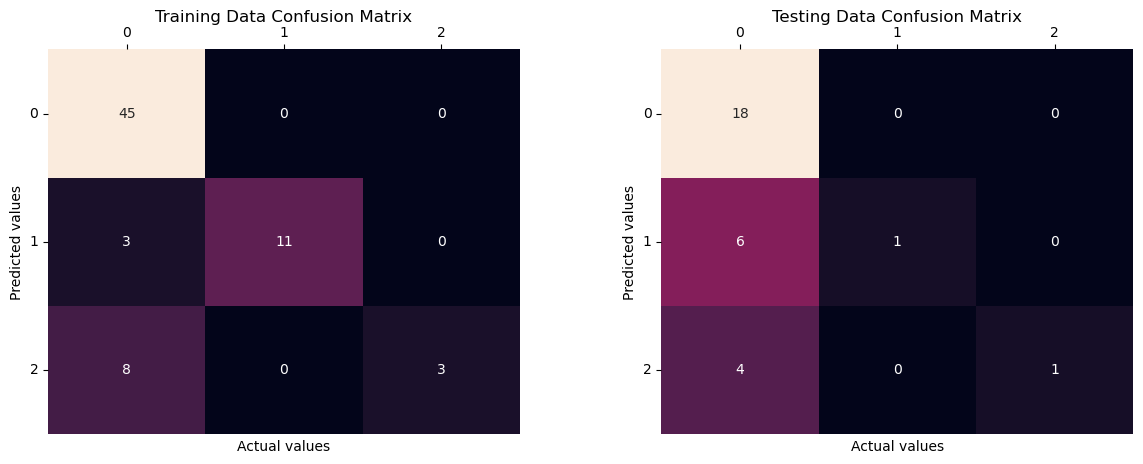

In [119]:
evaluation_results(y_train, y_train_estimated, y_test, y_predict)

In [120]:
cross_val_results(X, y, knn_2)

Scores: [0.75 0.6  0.6  0.35 0.35]
Mean: 0.53
Std: 0.15684387141358122


array([0.75, 0.6 , 0.6 , 0.35, 0.35])

In [87]:
knn_2 = KNeighborsClassifier(n_neighbors = 9, weights = 'uniform', p = 1)
knn_2.fit(X_train, y_train)
y_predict = knn_2.predict(X_test)
y_train_estimated = knn_2.predict(X_train)

## Logistic Regression

https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

In [121]:
from sklearn.linear_model import LogisticRegression

In [122]:
logreg = LogisticRegression(random_state=0, class_weight='balanced', C=1)
logreg.fit(X_train, y_train)
y_predict = logreg.predict(X_test)
y_train_estimated = logreg.predict(X_train)

Train accuracy:  1.0
Test accuracy:  0.6333333333333333
Train precision:  1.0
Test precision:  0.6333333333333333
Train recall:  1.0
Test recall:  0.6333333333333333
Train F1:  1.0
Test F1:  0.6333333333333333


C:\Users\Inesa\anaconda3\envs\L7_AI\Lib\site-packages\sklearn\metrics\_classification.py:1759: UserWarning: Note that pos_label (set to 'negative') is ignored when average != 'binary' (got 'micro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn(
C:\Users\Inesa\anaconda3\envs\L7_AI\Lib\site-packages\sklearn\metrics\_classification.py:1759: UserWarning: Note that pos_label (set to 'negative') is ignored when average != 'binary' (got 'micro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn(
C:\Users\Inesa\anaconda3\envs\L7_AI\Lib\site-packages\sklearn\metrics\_classification.py:1759: UserWarning: Note that pos_label (set to 'negative') is ignored when average != 'binary' (got 'micro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn(
C:\Users\Inesa\anaconda3\envs\L7_AI\Lib\site-packages\sklearn\metrics\_classification.py:1759: UserWarning: Note that pos_label (set to 'negative') is 

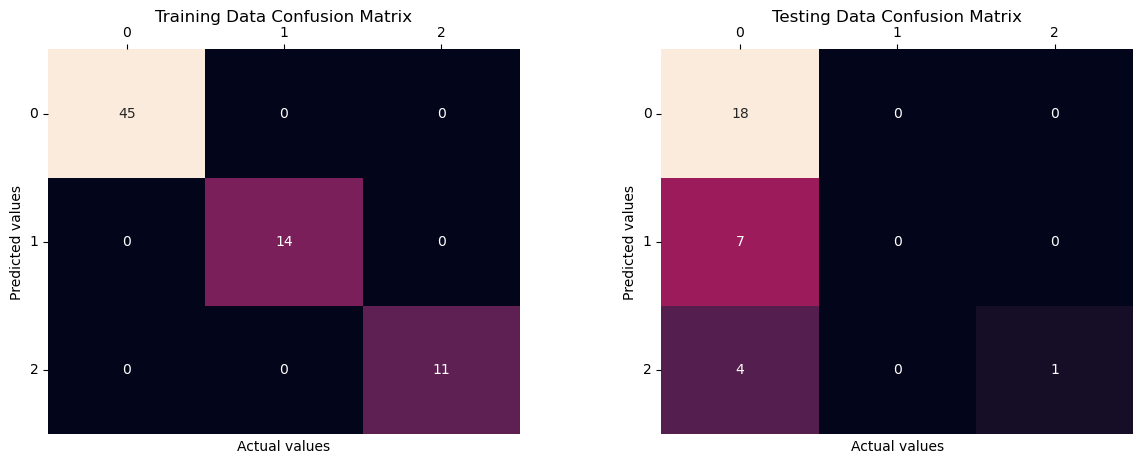

In [123]:
evaluation_results(y_train, y_train_estimated, y_test, y_predict)

In [125]:
cross_val_results(X, y, model=logreg, scoring='accuracy', cv=5)

Scores: [0.7  0.7  0.65 0.65 0.65]
Mean: 0.6699999999999999
Std: 0.024494897427831747


array([0.7 , 0.7 , 0.65, 0.65, 0.65])

## SVC(Support Vector Classification)

In [126]:
from sklearn.svm import SVC

In [127]:
svc_clf = SVC(class_weight='balanced', C=0.5)
svc_clf.fit(X_train, y_train)

y_predict = svc_clf.predict(X_test)
y_train_estimated = svc_clf.predict(X_train)

Train accuracy:  0.6714285714285714
Test accuracy:  0.23333333333333334
Train precision:  0.6714285714285714
Test precision:  0.23333333333333334
Train recall:  0.6714285714285714
Test recall:  0.23333333333333334
Train F1:  0.6714285714285714
Test F1:  0.23333333333333334


C:\Users\Inesa\anaconda3\envs\L7_AI\Lib\site-packages\sklearn\metrics\_classification.py:1759: UserWarning: Note that pos_label (set to 'negative') is ignored when average != 'binary' (got 'micro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn(
C:\Users\Inesa\anaconda3\envs\L7_AI\Lib\site-packages\sklearn\metrics\_classification.py:1759: UserWarning: Note that pos_label (set to 'negative') is ignored when average != 'binary' (got 'micro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn(
C:\Users\Inesa\anaconda3\envs\L7_AI\Lib\site-packages\sklearn\metrics\_classification.py:1759: UserWarning: Note that pos_label (set to 'negative') is ignored when average != 'binary' (got 'micro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn(
C:\Users\Inesa\anaconda3\envs\L7_AI\Lib\site-packages\sklearn\metrics\_classification.py:1759: UserWarning: Note that pos_label (set to 'negative') is 

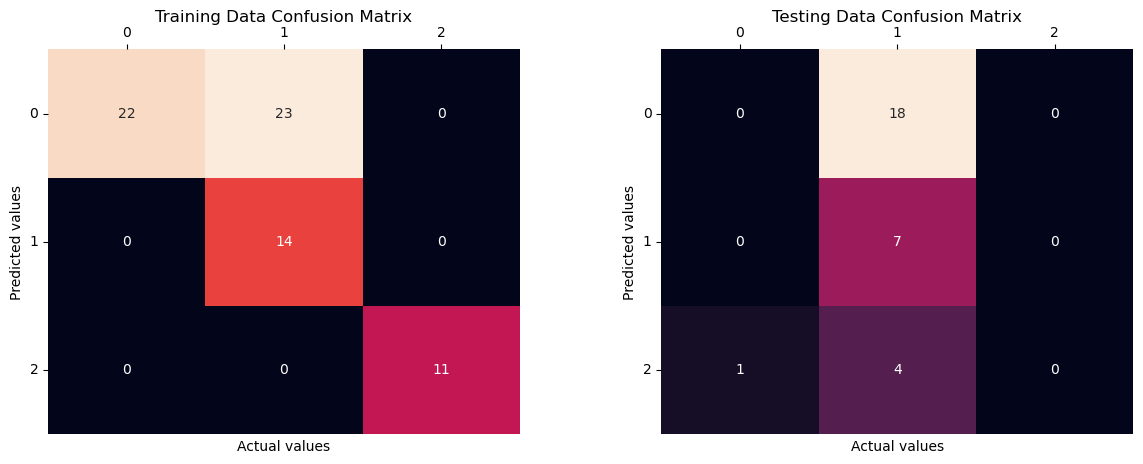

In [128]:
evaluation_results(y_train, y_train_estimated, y_test, y_predict)

In [130]:
cross_val_results(X, y, model=svc_clf, scoring='accuracy', cv=5)

Scores: [0.2 0.2 0.2 0.6 0.6]
Mean: 0.36000000000000004
Std: 0.19595917942265426


array([0.2, 0.2, 0.2, 0.6, 0.6])

## Naive Bayes

In [132]:
from sklearn.naive_bayes import MultinomialNB

In [134]:
mnb = MultinomialNB()

mnb.fit(X_train, y_train)

y_predict = mnb.predict(X_test)
y_train_estimated = mnb.predict(X_train)

Train accuracy:  0.6428571428571429
Test accuracy:  0.6
Train precision:  0.6428571428571429
Test precision:  0.6
Train recall:  0.6428571428571429
Test recall:  0.6
Train F1:  0.6428571428571429
Test F1:  0.6


C:\Users\Inesa\anaconda3\envs\L7_AI\Lib\site-packages\sklearn\metrics\_classification.py:1759: UserWarning: Note that pos_label (set to 'negative') is ignored when average != 'binary' (got 'micro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn(
C:\Users\Inesa\anaconda3\envs\L7_AI\Lib\site-packages\sklearn\metrics\_classification.py:1759: UserWarning: Note that pos_label (set to 'negative') is ignored when average != 'binary' (got 'micro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn(
C:\Users\Inesa\anaconda3\envs\L7_AI\Lib\site-packages\sklearn\metrics\_classification.py:1759: UserWarning: Note that pos_label (set to 'negative') is ignored when average != 'binary' (got 'micro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn(
C:\Users\Inesa\anaconda3\envs\L7_AI\Lib\site-packages\sklearn\metrics\_classification.py:1759: UserWarning: Note that pos_label (set to 'negative') is 

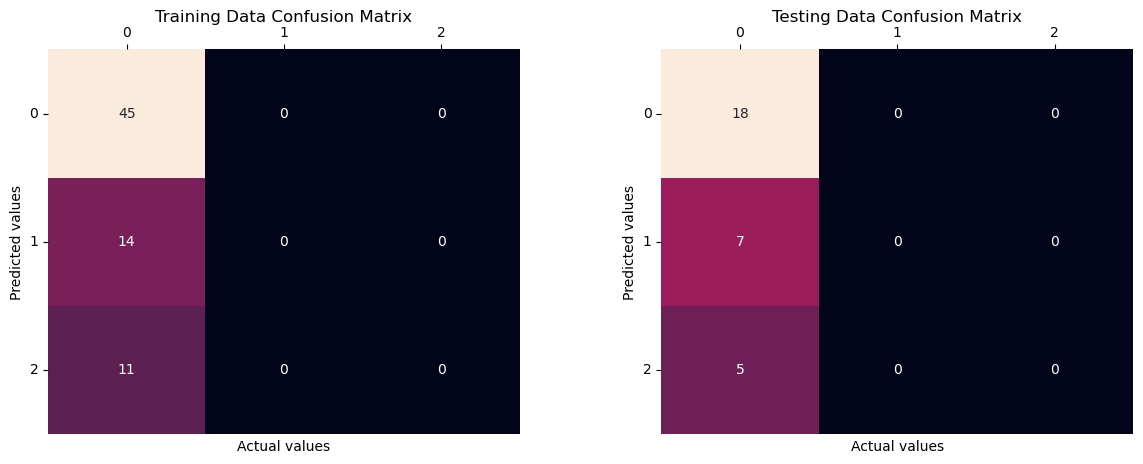

In [135]:
evaluation_results(y_train, y_train_estimated, y_test, y_predict)

In [138]:
cross_val_results(X, y, model=mnb, scoring='accuracy', cv=5)

Scores: [0.65 0.65 0.65 0.6  0.6 ]
Mean: 0.6300000000000001
Std: 0.024494897427831803


array([0.65, 0.65, 0.65, 0.6 , 0.6 ])

## Decision Tree

In [139]:
from sklearn.tree import DecisionTreeClassifier

In [140]:
dt = DecisionTreeClassifier()  
dt.fit(X_train, y_train)

y_predict = dt.predict(X_test)
y_train_estimated = dt.predict(X_train)

Train accuracy:  1.0
Test accuracy:  0.5333333333333333
Train precision:  1.0
Test precision:  0.5333333333333333
Train recall:  1.0
Test recall:  0.5333333333333333
Train F1:  1.0
Test F1:  0.5333333333333333


C:\Users\Inesa\anaconda3\envs\L7_AI\Lib\site-packages\sklearn\metrics\_classification.py:1759: UserWarning: Note that pos_label (set to 'negative') is ignored when average != 'binary' (got 'micro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn(
C:\Users\Inesa\anaconda3\envs\L7_AI\Lib\site-packages\sklearn\metrics\_classification.py:1759: UserWarning: Note that pos_label (set to 'negative') is ignored when average != 'binary' (got 'micro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn(
C:\Users\Inesa\anaconda3\envs\L7_AI\Lib\site-packages\sklearn\metrics\_classification.py:1759: UserWarning: Note that pos_label (set to 'negative') is ignored when average != 'binary' (got 'micro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn(
C:\Users\Inesa\anaconda3\envs\L7_AI\Lib\site-packages\sklearn\metrics\_classification.py:1759: UserWarning: Note that pos_label (set to 'negative') is 

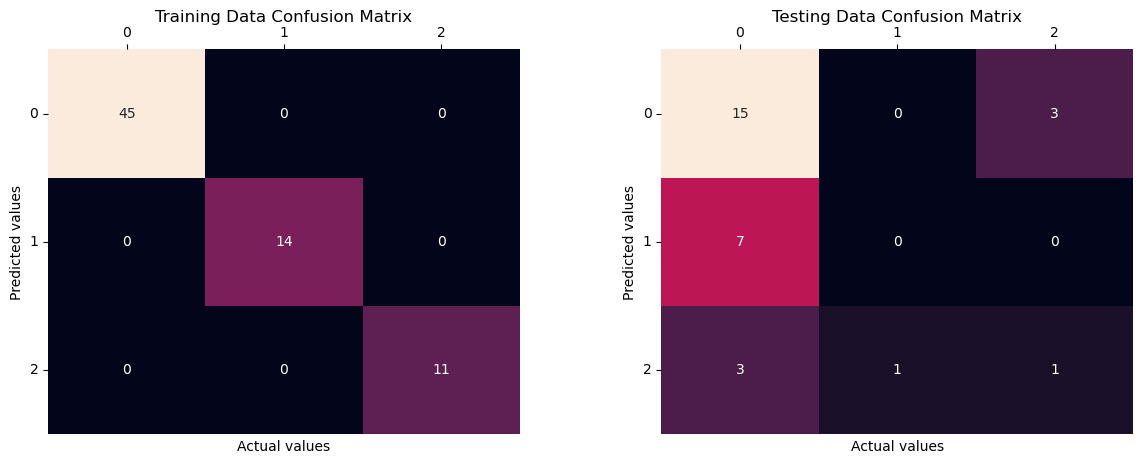

In [141]:
evaluation_results(y_train, y_train_estimated, y_test, y_predict)

In [144]:
cross_val_results(X, y, model=dt, scoring='accuracy', cv=5)

Scores: [0.65 0.7  0.6  0.45 0.65]
Mean: 0.6100000000000001
Std: 0.08602325267042626


array([0.65, 0.7 , 0.6 , 0.45, 0.65])

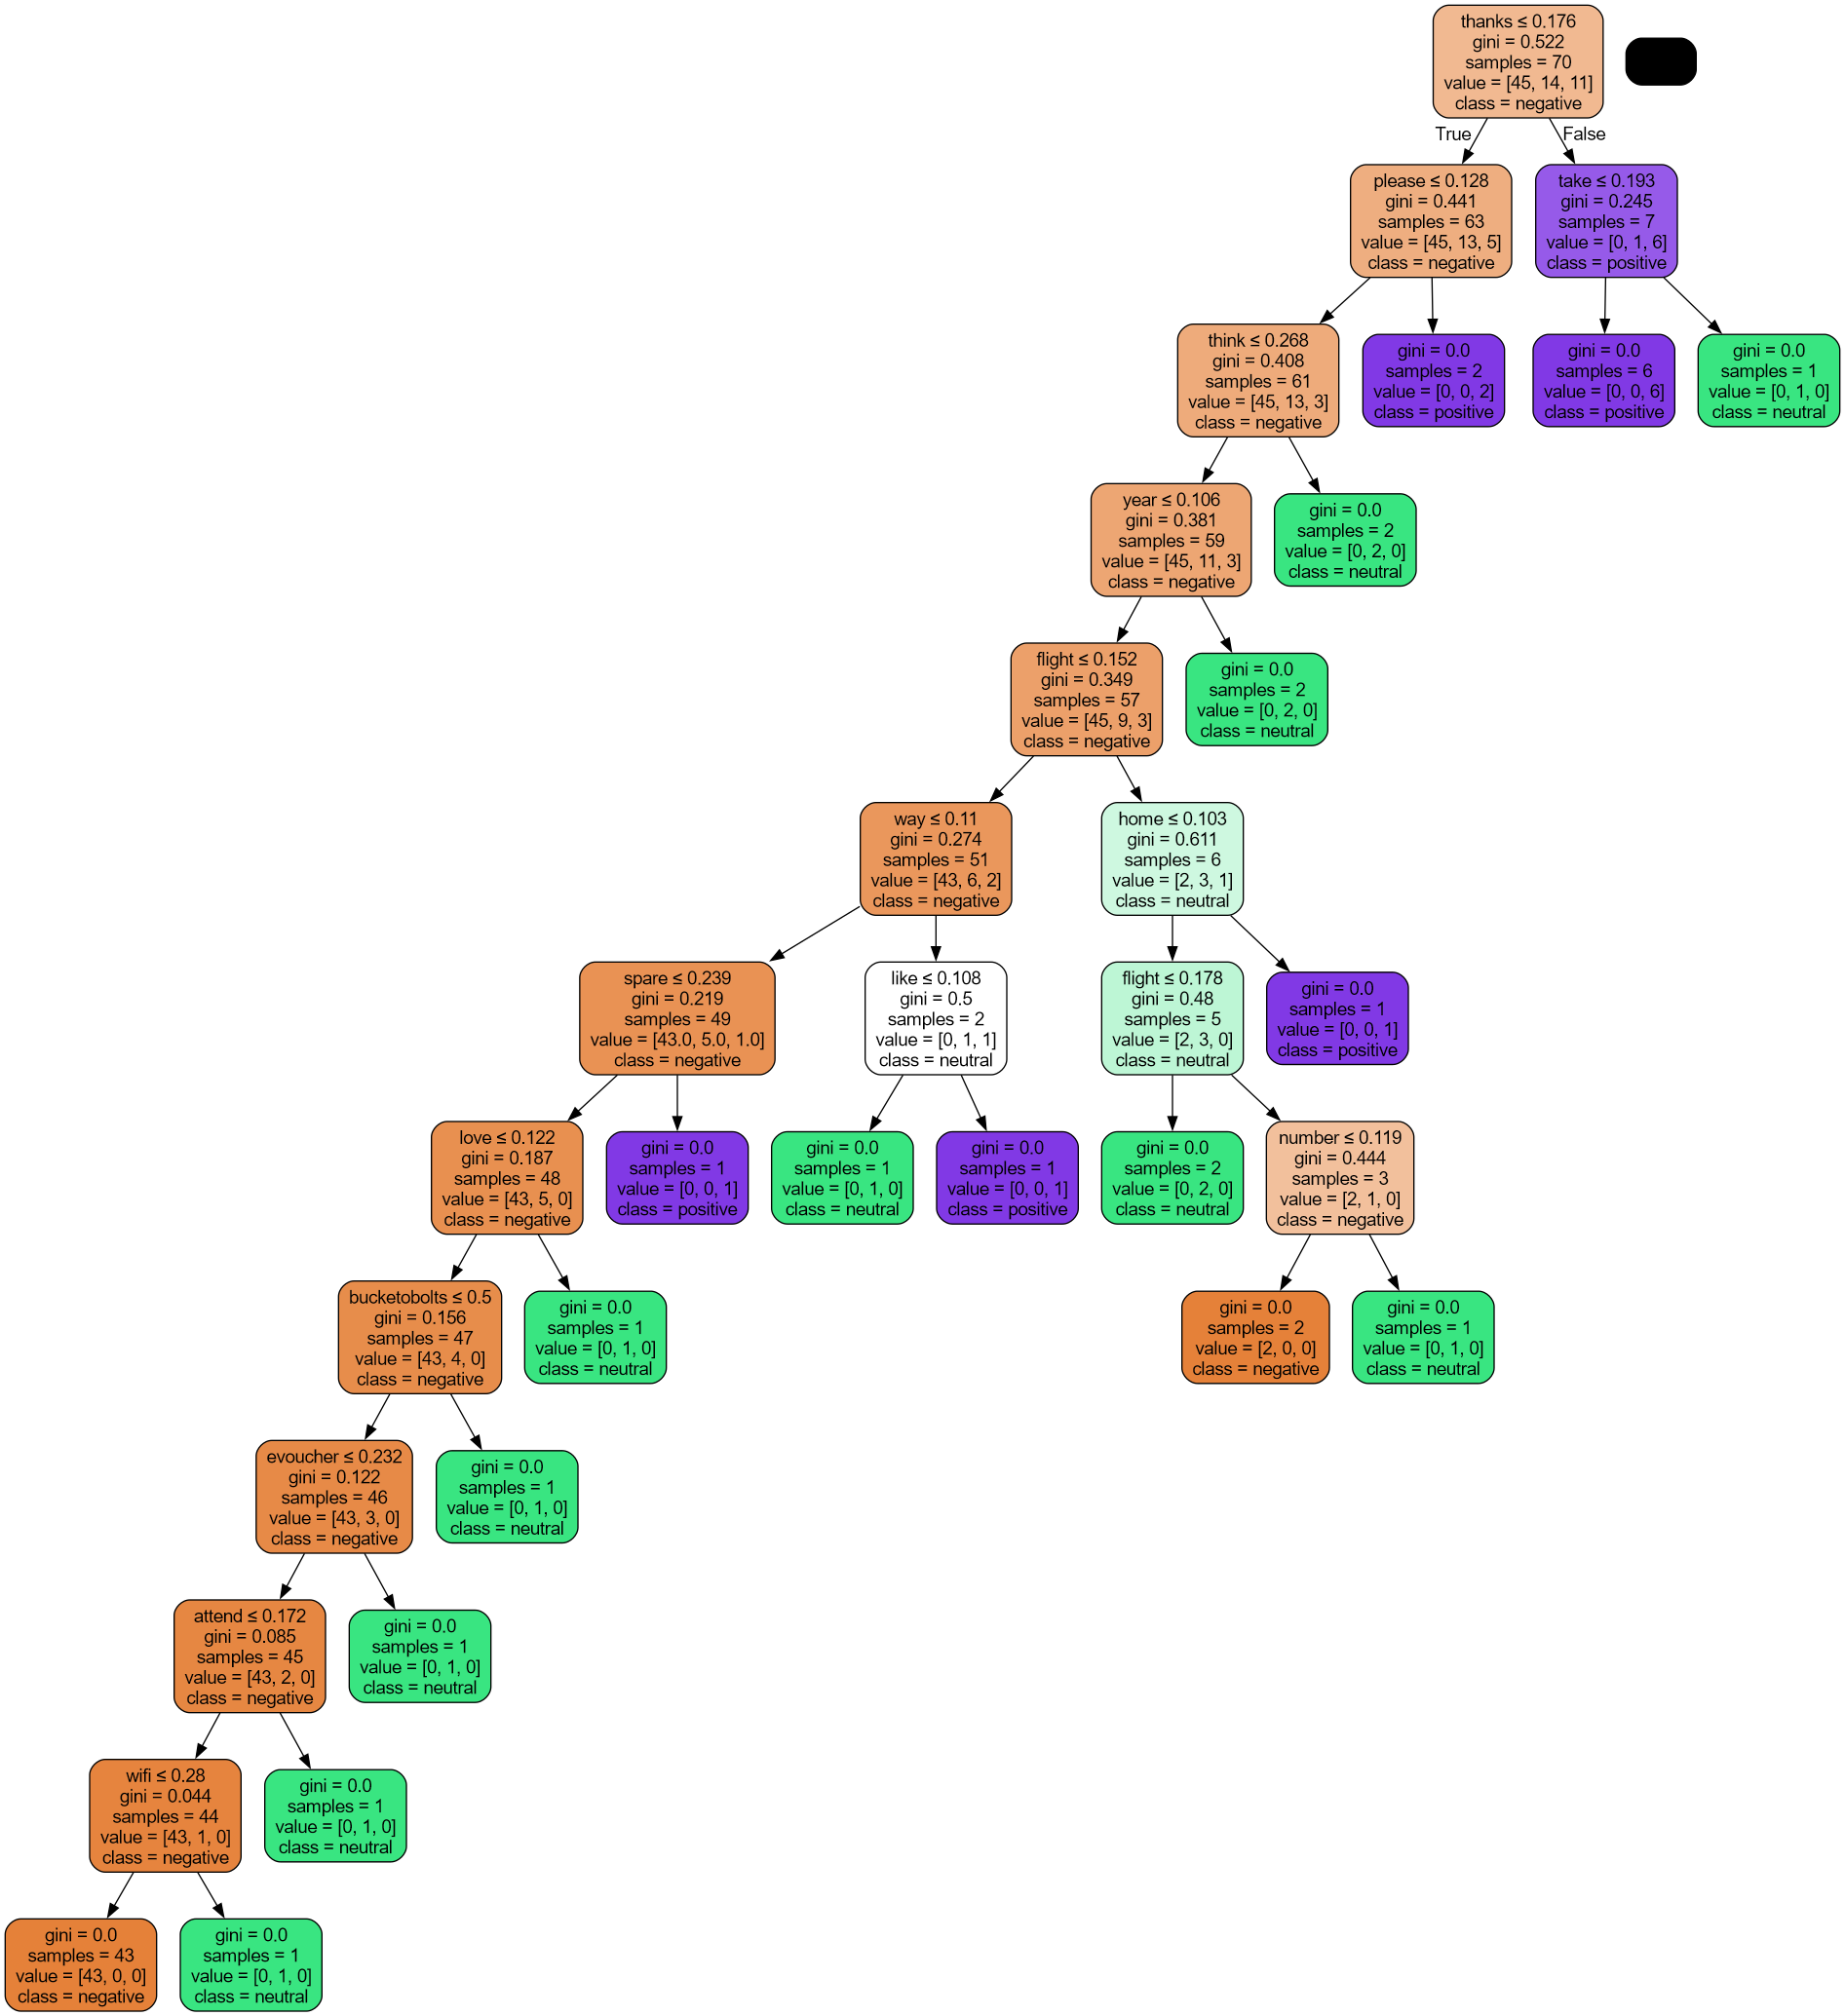

In [142]:
from sklearn.tree import export_graphviz
from six import StringIO  
from IPython.display import Image  
import pydotplus

dot_data = StringIO()
export_graphviz(dt, out_file=dot_data,  
                filled=True, rounded=True,
                special_characters=True, feature_names = X.columns,
                class_names=['negative', 'neutral', 'positive'])
graph = pydotplus.graph_from_dot_data(dot_data.getvalue())  
graph.write_png('diabetes.png')
Image(graph.create_png())

In [145]:
dt_1 = DecisionTreeClassifier(criterion = 'entropy', 
                              class_weight = 'balanced', 
                              max_depth = 20, 
                              min_samples_leaf = 10)  

dt_1.fit(X_train, y_train)

y_predict = dt_1.predict(X_test)
y_train_estimated = dt_1.predict(X_train)

Train accuracy:  0.6142857142857143
Test accuracy:  0.5666666666666667
Train precision:  0.6142857142857143
Test precision:  0.5666666666666667
Train recall:  0.6142857142857143
Test recall:  0.5666666666666667
Train F1:  0.6142857142857143
Test F1:  0.5666666666666667


C:\Users\Inesa\anaconda3\envs\L7_AI\Lib\site-packages\sklearn\metrics\_classification.py:1759: UserWarning: Note that pos_label (set to 'negative') is ignored when average != 'binary' (got 'micro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn(
C:\Users\Inesa\anaconda3\envs\L7_AI\Lib\site-packages\sklearn\metrics\_classification.py:1759: UserWarning: Note that pos_label (set to 'negative') is ignored when average != 'binary' (got 'micro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn(
C:\Users\Inesa\anaconda3\envs\L7_AI\Lib\site-packages\sklearn\metrics\_classification.py:1759: UserWarning: Note that pos_label (set to 'negative') is ignored when average != 'binary' (got 'micro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn(
C:\Users\Inesa\anaconda3\envs\L7_AI\Lib\site-packages\sklearn\metrics\_classification.py:1759: UserWarning: Note that pos_label (set to 'negative') is 

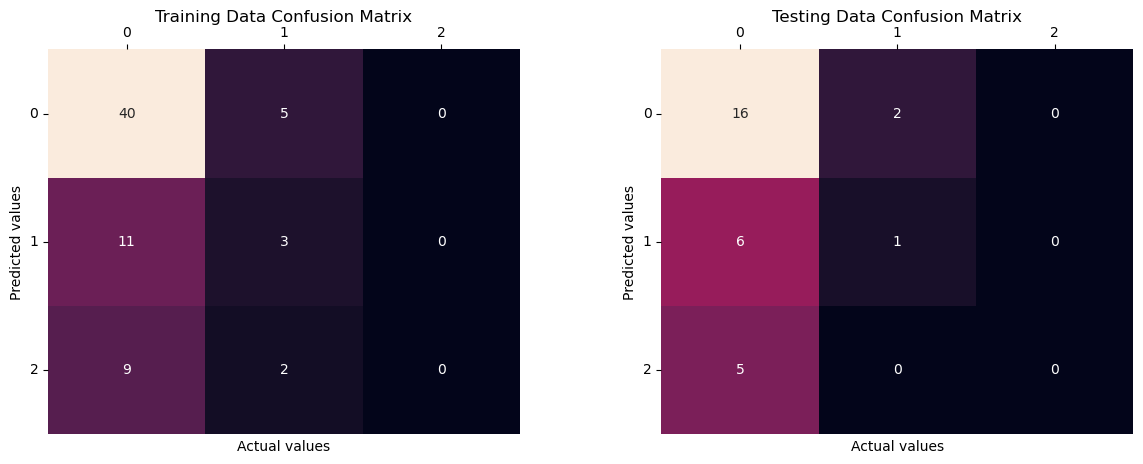

In [146]:
evaluation_results(y_train, y_train_estimated, y_test, y_predict)

In [148]:
cross_val_results(X, y, model=dt_1, scoring='accuracy', cv=5)

Scores: [0.6  0.65 0.1  0.55 0.55]
Mean: 0.49000000000000005
Std: 0.19849433241279207


array([0.6 , 0.65, 0.1 , 0.55, 0.55])

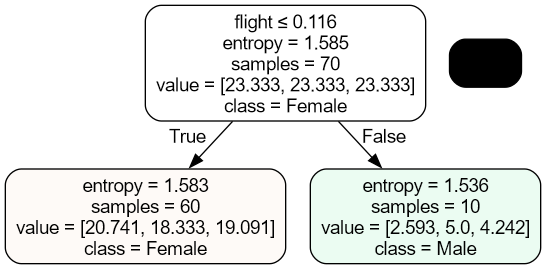

In [149]:
from sklearn.tree import export_graphviz
from six import StringIO  
from IPython.display import Image  
import pydotplus

dot_data = StringIO()
export_graphviz(dt_1, out_file=dot_data,  
                filled=True, rounded=True,
                special_characters=True, feature_names = X.columns,
                class_names=["Female", "Male"])
graph = pydotplus.graph_from_dot_data(dot_data.getvalue())  
graph.write_png('diabetes.png')
Image(graph.create_png())